# Assignment 2 Part B — Dialer Campaign Analytics

**Data:** `accounts.csv` (20,000 accounts) and `calls.csv` (70,235 call attempts), produced by `gen_data.py` (unchanged).

**Data dictionary (verified against the files):**

| File | Column | Type | Meaning |
|---|---|---|---|
| accounts | `account_id` | str (`A#####`) | Unique account key |
| accounts | `state` | str | `MH, KA, TN, UP, BR, GJ` |
| accounts | `batch` | str | Dialer batch `B1`–`B8` |
| accounts | `dpd` | int | Days past due (1–120) |
| accounts | `outstanding` | int | Outstanding amount (2,009–79,999) |
| calls | `account_id` | str | FK → accounts |
| calls | `called_at` | datetime | 2026-08-01 08:00 → 2026-08-30 18:59 |
| calls | `disposition` | str | `NO_ANSWER`, `WRONG_NUMBER`, `RPC_NO_PTP`, `PTP` |
| calls | `days_to_promise` | float/NaN | Days until promised payment; **only** on PTP calls (1–14) |
| calls | `ptp_kept` | float/NaN | `1.0` kept, `0.0` broken; **only** on PTP calls |

**Metric definitions used below:**

- **Connected** = disposition ∈ {`WRONG_NUMBER`, `RPC_NO_PTP`, `PTP`} (call answered, even by wrong party).
- **RPC** (right-party contact) = disposition ∈ {`RPC_NO_PTP`, `PTP`} (connected minus wrong number).
- **PTP** = disposition = `PTP`. PTP can only occur on an RPC, so the **PTP-rate denominator is RPCs** (per-dial rates are also shown for audit).
- **Kept PTP** = `ptp_kept == 1.0`; kept-rate denominator = PTP calls only.


In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker

pd.set_option("display.width", 140)

accounts = pd.read_csv("accounts.csv")
calls = pd.read_csv("calls.csv", parse_dates=["called_at"])

print(f"accounts: {accounts.shape}   calls: {calls.shape}")
print("\naccounts dtypes:\n", accounts.dtypes.to_string())
print("\ncalls dtypes:\n", calls.dtypes.to_string())
print("\ncalls head:\n", calls.head().to_string())
print("\nDisposition counts:\n", calls["disposition"].value_counts().to_string())

accounts: (20000, 5)   calls: (70235, 5)

accounts dtypes:
 account_id       str
state            str
batch            str
dpd            int64
outstanding    int64

calls dtypes:
 account_id                    str
called_at          datetime64[us]
disposition                   str
days_to_promise           float64
ptp_kept                  float64

calls head:
   account_id           called_at disposition  days_to_promise  ptp_kept
0     A00000 2026-08-01 14:30:00   NO_ANSWER              NaN       NaN
1     A00000 2026-08-25 13:56:00   NO_ANSWER              NaN       NaN
2     A00000 2026-08-04 12:05:00   NO_ANSWER              NaN       NaN
3     A00000 2026-08-23 17:28:00   NO_ANSWER              NaN       NaN
4     A00000 2026-08-01 17:12:00   NO_ANSWER              NaN       NaN

Disposition counts:
 disposition
NO_ANSWER       52213
RPC_NO_PTP      12624
PTP              3892
WRONG_NUMBER     1506


## 1. Join calls → accounts (validate 1:many)

Join key: `account_id`. Expected relationship: **one row per account** on the accounts side, **many rows per account** on the calls side. We use `validate="many_to_one"` plus explicit row-count and merge-indicator checks so any accidental row multiplication or orphan call fails loudly.

In [2]:
assert accounts["account_id"].is_unique, "accounts.account_id is not unique — join would multiply rows"

n_calls_before = len(calls)
df = calls.merge(accounts, on="account_id", how="left", validate="many_to_one", indicator=True)

assert len(df) == n_calls_before, f"row count changed: {n_calls_before} -> {len(df)}"
orphans = (df["_merge"] != "both").sum()
assert orphans == 0, f"{orphans} calls have no matching account"
df = df.drop(columns="_merge")

calls_per_account = df.groupby("account_id").size()
print(f"Joined frame: {len(df):,} rows == calls rows ({n_calls_before:,}) — 1:many join, no multiplication")
print(f"Orphan calls: {orphans} | Accounts with 0 calls: {(~accounts['account_id'].isin(calls['account_id'])).sum()}")
print(f"Calls per account: min={calls_per_account.min()}, max={calls_per_account.max()}, mean={calls_per_account.mean():.2f}")

Joined frame: 70,235 rows == calls rows (70,235) — 1:many join, no multiplication
Orphan calls: 0 | Accounts with 0 calls: 0
Calls per account: min=1, max=6, mean=3.51


In [3]:
# Verify the disposition vocabulary before building any metric flags
EXPECTED_DISPOSITIONS = {"NO_ANSWER", "WRONG_NUMBER", "RPC_NO_PTP", "PTP"}
observed = set(calls["disposition"].unique())
unexpected = observed - EXPECTED_DISPOSITIONS
print("Observed dispositions:", sorted(observed))
print("Unexpected values:", sorted(unexpected) if unexpected else "none")

CONNECTED = {"WRONG_NUMBER", "RPC_NO_PTP", "PTP"}
RPC = {"RPC_NO_PTP", "PTP"}

df["is_connected"] = df["disposition"].isin(CONNECTED)
df["is_rpc"] = df["disposition"].isin(RPC)
df["is_ptp"] = df["disposition"].eq("PTP")

print(f"\nConnected={df['is_connected'].sum():,}  RPC={df['is_rpc'].sum():,}  PTP={df['is_ptp'].sum():,}  (of {len(df):,} calls)")
print(f"RPC check: connected ({df['is_connected'].sum():,}) == RPC ({df['is_rpc'].sum():,}) + WRONG_NUMBER ({df['disposition'].eq('WRONG_NUMBER').sum():,}) ->",
      df['is_connected'].sum() == df['is_rpc'].sum() + df['disposition'].eq('WRONG_NUMBER').sum())

Observed dispositions: ['NO_ANSWER', 'PTP', 'RPC_NO_PTP', 'WRONG_NUMBER']
Unexpected values: none

Connected=18,022  RPC=16,516  PTP=3,892  (of 70,235 calls)
RPC check: connected (18,022) == RPC (16,516) + WRONG_NUMBER (1,506) -> True


## 2. Connection rate by hour of day

Rate = connected calls / all calls placed in that hour. Both numerator and denominator are printed for audit.

      calls_placed  connected  connection_rate
hour                                          
8             6411       1387           0.2163
9             6464       1439           0.2226
10            6341       2012           0.3173
11            6302       2014           0.3196
12            6443       1369           0.2125
13            6481       1387           0.2140
14            6444       1387           0.2152
15            6233       1349           0.2164
16            6453       1445           0.2239
17            6313       2100           0.3326
18            6350       2133           0.3359

Overall connection rate: 0.2566 (18,022/70,235)


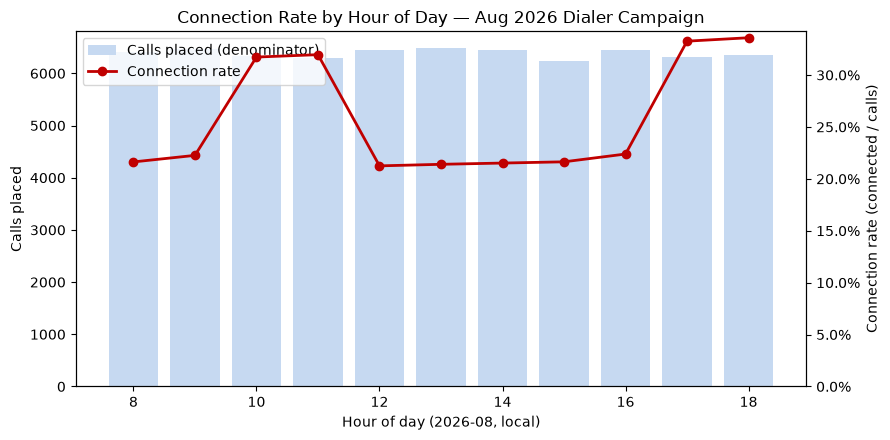

In [4]:
hour = df["called_at"].dt.hour
by_hour = (df.assign(hour=hour)
             .groupby("hour")
             .agg(calls_placed=("is_connected", "size"),
                  connected=("is_connected", "sum")))
by_hour["connection_rate"] = (by_hour["connected"] / by_hour["calls_placed"]).round(4)
assert (by_hour["calls_placed"] > 0).all(), "hour bucket with zero denominator"
print(by_hour.to_string())
print(f"\nOverall connection rate: {df['is_connected'].mean():.4f} ({df['is_connected'].sum():,}/{len(df):,})")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(by_hour.index, by_hour["calls_placed"], color="#c6d9f1", label="Calls placed (denominator)")
ax.set_xlabel("Hour of day (2026-08, local)")
ax.set_ylabel("Calls placed")
ax2 = ax.twinx()
ax2.plot(by_hour.index, by_hour["connection_rate"], marker="o", color="#c00000", linewidth=2, label="Connection rate")
ax2.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1))
ax2.set_ylabel("Connection rate (connected / calls)")
ax2.set_ylim(0)
ax.set_title("Connection Rate by Hour of Day — Aug 2026 Dialer Campaign")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left")
fig.tight_layout()
plt.show()

## 3. Weekday vs weekend connection rate

`called_at.dayofweek >= 5` marks Saturday/Sunday. Rate denominator: all calls placed in each group.

          calls_placed  connected  connection_rate
day_type                                          
Weekday          46765      11153           0.2385
Weekend          23470       6869           0.2927

Weekend − Weekday lift: +0.0542 (29.27% vs 23.85%)


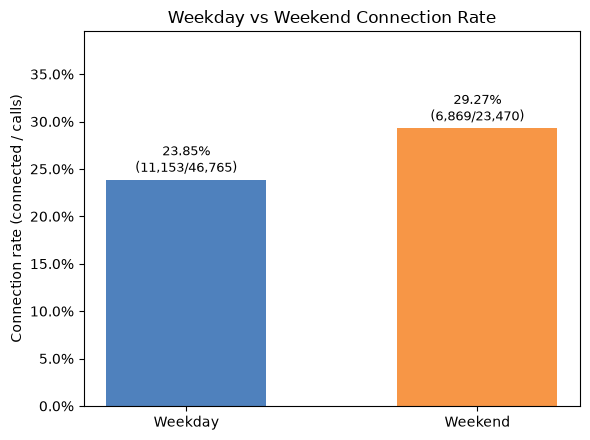

In [5]:
df["day_type"] = np.where(df["called_at"].dt.dayofweek >= 5, "Weekend", "Weekday")

by_day = (df.groupby("day_type")
            .agg(calls_placed=("is_connected", "size"),
                 connected=("is_connected", "sum")))
by_day["connection_rate"] = (by_day["connected"] / by_day["calls_placed"]).round(4)
print(by_day.to_string())

wk = by_day.loc["Weekday", "connection_rate"]
we = by_day.loc["Weekend", "connection_rate"]
print(f"\nWeekend − Weekday lift: {we - wk:+.4f} ({we:.2%} vs {wk:.2%})")

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(by_day.index, by_day["connection_rate"], color=["#4f81bd", "#f79646"], width=0.55)
for bar, (_, row) in zip(bars, by_day.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004,
            f"{row['connection_rate']:.2%}\n({int(row['connected']):,}/{int(row['calls_placed']):,})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Connection rate (connected / calls)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_ylim(0, max(we, wk) * 1.35)
ax.set_title("Weekday vs Weekend Connection Rate")
fig.tight_layout()
plt.show()

## 4. PTP rate by DPD band

**Denominator = right-party contacts (RPCs)** in each band: a PTP is only possible after an RPC (non-RPC calls can never carry a PTP), so RPC is the semantically correct denominator. Per-dial rates are shown as a secondary column for audit. Zero-denominator guards included.

Bands with zero RPC denominator: 0
          calls_placed  rpcs  ptps  ptp_rate_per_rpc  ptp_rate_per_call
dpd_band                                                               
1–30             17611  4094  1151            0.2811             0.0654
31–60            17381  4119  1055            0.2561             0.0607
61–90            17636  4199   900            0.2143             0.0510
91–120           17607  4104   786            0.1915             0.0446

Overall PTP/RPC: 3892/16516 = 0.2357


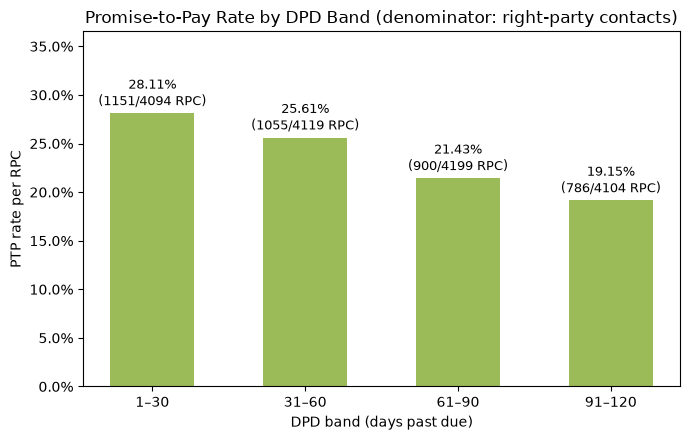

In [6]:
dpd_band = pd.cut(df["dpd"], bins=[0, 30, 60, 90, 120],
                   labels=["1–30", "31–60", "61–90", "91–120"], include_lowest=True)

by_band = (df.assign(dpd_band=dpd_band)
             .groupby("dpd_band", observed=True)
             .agg(calls_placed=("is_ptp", "size"),
                  rpcs=("is_rpc", "sum"),
                  ptps=("is_ptp", "sum")))

zero_den = (by_band["rpcs"] == 0).sum()
print(f"Bands with zero RPC denominator: {zero_den}")
by_band["ptp_rate_per_rpc"] = np.where(by_band["rpcs"] > 0, by_band["ptps"] / by_band["rpcs"], np.nan).round(4)
by_band["ptp_rate_per_call"] = (by_band["ptps"] / by_band["calls_placed"]).round(4)
print(by_band.to_string())
print(f"\nOverall PTP/RPC: {df['is_ptp'].sum()}/{df['is_rpc'].sum()} = {df['is_ptp'].sum()/df['is_rpc'].sum():.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(by_band.index.astype(str), by_band["ptp_rate_per_rpc"], color="#9bbb59", width=0.55)
for bar, (_, row) in zip(bars, by_band.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.004,
            f"{row['ptp_rate_per_rpc']:.2%}\n({int(row['ptps'])}/{int(row['rpcs'])} RPC)",
            ha="center", va="bottom", fontsize=9)
ax.set_xlabel("DPD band (days past due)")
ax.set_ylabel("PTP rate per RPC")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_ylim(0, by_band["ptp_rate_per_rpc"].max() * 1.3)
ax.set_title("Promise-to-Pay Rate by DPD Band (denominator: right-party contacts)")
fig.tight_layout()
plt.show()

## 5. Kept-PTP rate by days until promise

**Filtered to PTP calls only** (that is the population for which a PTP exists). Kept = `ptp_kept == 1.0`.

                 ptps  kept  kept_rate
days_to_promise                       
1                 259   162     0.6255
2                 280   194     0.6929
3                 287   181     0.6307
4                 306   188     0.6144
5                 267   183     0.6854
6                 266    84     0.3158
7                 263    90     0.3422
8                 257    88     0.3424
9                 300   103     0.3433
10                308   105     0.3409
11                278   107     0.3849
12                291    95     0.3265
13                270    99     0.3667
14                260    87     0.3346

Overall kept rate: 1766/3892 = 0.4538
Days ≤ 5: 908/1399 = 0.6490
Days > 5: 858/2493 = 0.3442


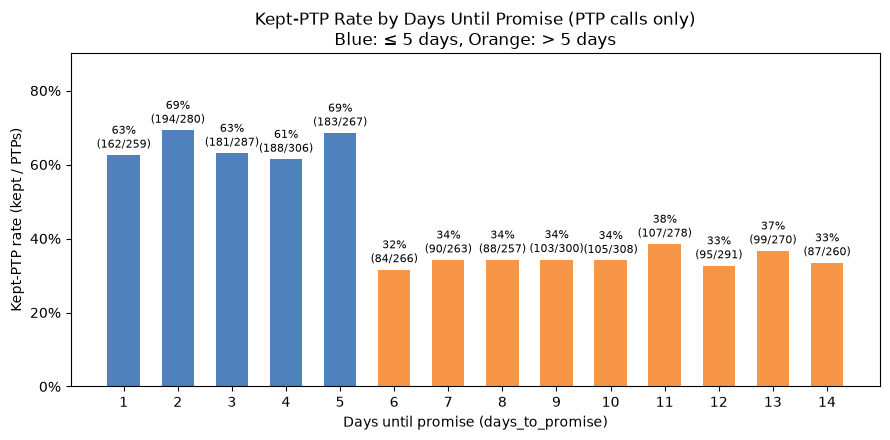

In [7]:
ptp = df[df["is_ptp"]].copy()
ptp["days_to_promise"] = ptp["days_to_promise"].astype(int)

by_days = (ptp.groupby("days_to_promise")
              .agg(ptps=("ptp_kept", "size"),
                   kept=("ptp_kept", lambda s: int(s.eq(1).sum()))))
assert (by_days["ptps"] > 0).all(), "days bucket with zero PTP denominator"
by_days["kept_rate"] = (by_days["kept"] / by_days["ptps"]).round(4)
print(by_days.to_string())
print(f"\nOverall kept rate: {int(by_days['kept'].sum())}/{int(by_days['ptps'].sum())} = {by_days['kept'].sum()/by_days['ptps'].sum():.4f}")

fast = ptp[ptp["days_to_promise"] <= 5]
slow = ptp[ptp["days_to_promise"] > 5]
print(f"Days ≤ 5: {fast['ptp_kept'].eq(1).sum()}/{len(fast)} = {fast['ptp_kept'].eq(1).mean():.4f}")
print(f"Days > 5: {slow['ptp_kept'].eq(1).sum()}/{len(slow)} = {slow['ptp_kept'].eq(1).mean():.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
colors = ["#4f81bd" if d <= 5 else "#f79646" for d in by_days.index]
bars = ax.bar(by_days.index.astype(str), by_days["kept_rate"], color=colors, width=0.6)
for bar, (_, row) in zip(bars, by_days.iterrows()):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
            f"{row['kept_rate']:.0%}\n({int(row['kept'])}/{int(row['ptps'])})",
            ha="center", va="bottom", fontsize=8)
ax.set_xlabel("Days until promise (days_to_promise)")
ax.set_ylabel("Kept-PTP rate (kept / PTPs)")
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_ylim(0, by_days["kept_rate"].max() * 1.3)
ax.set_title("Kept-PTP Rate by Days Until Promise (PTP calls only)\nBlue: ≤ 5 days, Orange: > 5 days")
fig.tight_layout()
plt.show()

## 6. Data-quality report

Missing values, duplicate records, orphans, out-of-range / unexpected values, and denominator checks.

In [8]:
print("=== Missing values ===")
nulls = pd.DataFrame({"accounts_nulls": accounts.isna().sum(), "calls_nulls": calls.isna().sum()})
print(nulls.to_string())
print("Note: days_to_promise & ptp_kept are null BY DESIGN except on PTP calls.")

print("\n=== Duplicate records ===")
dup_acc = int(accounts.duplicated().sum())
dup_calls = int(calls.duplicated().sum())
print(f"Duplicate account rows: {dup_acc} | duplicate account_ids: {int(accounts['account_id'].duplicated().sum())}")
print(f"Exact duplicate call rows: {dup_calls}")
if dup_calls:
    print(calls[calls.duplicated(keep=False)].sort_values(["account_id", "called_at"]).to_string(index=False))
    print("-> coincidental RNG collisions (same account, timestamp, disposition); drop before counting volumes.")

print("\n=== Referential integrity ===")
print("Calls without account:", int((~calls["account_id"].isin(accounts["account_id"])).sum()))
print("Accounts without calls:", int((~accounts["account_id"].isin(calls["account_id"])).sum()))

print("\n=== Unexpected / out-of-range values ===")
print("Unexpected dispositions:", sorted(set(calls["disposition"]) - EXPECTED_DISPOSITIONS) or "none")
print("dpd range:", (int(accounts["dpd"].min()), int(accounts["dpd"].max())), "(expected 1–120)")
print("outstanding range:", (int(accounts["outstanding"].min()), int(accounts["outstanding"].max())))
print("call hour range:", (int(calls["called_at"].dt.hour.min()), int(calls["called_at"].dt.hour.max())), "(expected 8–18)")
print("calls outside Aug 2026:", int((~calls["called_at"].dt.to_period("M").eq(pd.Period("2026-08"))).sum()))

print("\n=== PTP field consistency ===")
non_ptp_with_days = int(calls.loc[calls["disposition"] != "PTP", "days_to_promise"].notna().sum())
non_ptp_with_kept = int(calls.loc[calls["disposition"] != "PTP", "ptp_kept"].notna().sum())
ptp_missing_days = int(calls.loc[calls["disposition"] == "PTP", "days_to_promise"].isna().sum())
ptp_missing_kept = int(calls.loc[calls["disposition"] == "PTP", "ptp_kept"].isna().sum())
print("non-PTP rows with days_to_promise:", non_ptp_with_days, "| non-PTP rows with ptp_kept:", non_ptp_with_kept)
print("PTP rows missing days_to_promise:", ptp_missing_days, "| PTP rows missing ptp_kept:", ptp_missing_kept)
print("ptp_kept values outside {0,1}:", int((~calls["ptp_kept"].isin([0.0, 1.0]) & calls["ptp_kept"].notna()).sum()))
print("days_to_promise range on PTPs:", (calls.loc[calls['disposition']=='PTP','days_to_promise'].min(), calls.loc[calls['disposition']=='PTP','days_to_promise'].max()), "(expected 1–14)")

print("\n=== Zero-denominator checks (all metrics above) ===")
print("Hour buckets with 0 calls:", int((by_hour["calls_placed"] == 0).sum()))
print("Day-type groups with 0 calls:", int((by_day["calls_placed"] == 0).sum()))
print("DPD bands with 0 RPCs:", int((by_band["rpcs"] == 0).sum()))
print("Days-to-promise buckets with 0 PTPs:", int((by_days["ptps"] == 0).sum()))

=== Missing values ===
                 accounts_nulls  calls_nulls
account_id                  0.0          0.0
batch                       0.0          NaN
called_at                   NaN          0.0
days_to_promise             NaN      66343.0
disposition                 NaN          0.0
dpd                         0.0          NaN
outstanding                 0.0          NaN
ptp_kept                    NaN      66343.0
state                       0.0          NaN
Note: days_to_promise & ptp_kept are null BY DESIGN except on PTP calls.

=== Duplicate records ===
Duplicate account rows: 0 | duplicate account_ids: 0
Exact duplicate call rows: 4
account_id           called_at disposition  days_to_promise  ptp_kept
    A13496 2026-08-30 08:43:00   NO_ANSWER              NaN       NaN
    A13496 2026-08-30 08:43:00   NO_ANSWER              NaN       NaN
    A13928 2026-08-30 14:46:00   NO_ANSWER              NaN       NaN
    A13928 2026-08-30 14:46:00   NO_ANSWER              NaN      

## 7. Anomaly investigation — wrong-number outcomes

`gen_data.py` defines `wrong = connected & (random < rate)`, so a wrong number can only be detected **after the call is answered**. The correct denominator is therefore **connected calls** (`WRONG_NUMBER + RPC_NO_PTP + PTP`) in each segment — never all dials. Every segment below reports its numerator (`WRONG_NUMBER`), denominator (connected calls), and sample size. No segment is called anomalous without computing its rate first.

In [9]:
df["is_wrong"] = df["disposition"].eq("WRONG_NUMBER")
wrong_n, conn_n = int(df["is_wrong"].sum()), int(df["is_connected"].sum())
print(f"Overall wrong-number rate among connected calls: {wrong_n:,}/{conn_n:,} = {wrong_n/conn_n:.4f}")
print("Denominator = connected calls (wrong number is only observable on answered calls).")

Overall wrong-number rate among connected calls: 1,506/18,022 = 0.0836
Denominator = connected calls (wrong number is only observable on answered calls).


       connected  wrong  wrong_rate
batch                              
B7          2284    251      0.1099
B2          2194    183      0.0834
B8          2248    185      0.0823
B1          2230    183      0.0821
B3          2349    191      0.0813
B6          2274    175      0.0770
B4          2266    174      0.0768
B5          2177    164      0.0753


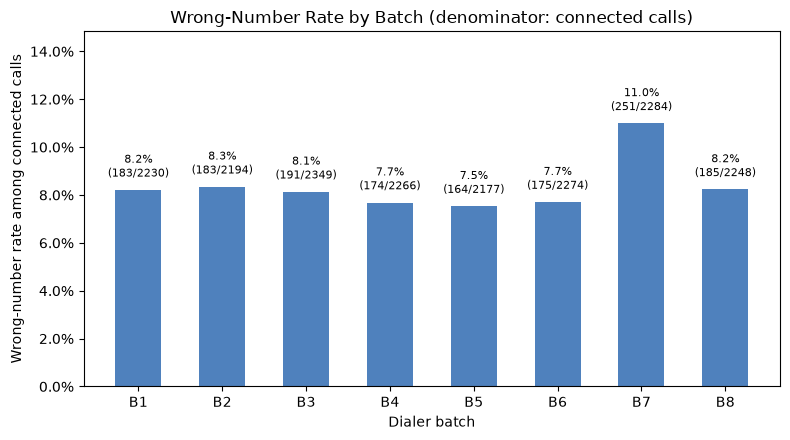

In [10]:
wr_batch = (df.groupby("batch")
              .agg(connected=("is_connected", "sum"), wrong=("is_wrong", "sum")))
assert (wr_batch["connected"] > 0).all(), "batch with zero connected denominator"
wr_batch["wrong_rate"] = (wr_batch["wrong"] / wr_batch["connected"]).round(4)
print(wr_batch.sort_values("wrong_rate", ascending=False).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
wb = wr_batch.sort_index()
bars = ax.bar(wb.index, wb["wrong_rate"], width=0.55,
              color=["#c00000" if r > 2 * wb["wrong_rate"].median() else "#4f81bd" for r in wb["wrong_rate"]])
for bar, (_, row) in zip(bars, wb.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
            f"{row['wrong_rate']:.1%}\n({int(row['wrong'])}/{int(row['connected'])})",
            ha="center", va="bottom", fontsize=8)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_xlabel("Dialer batch")
ax.set_ylabel("Wrong-number rate among connected calls")
ax.set_ylim(0, wb["wrong_rate"].max() * 1.35)
ax.set_title("Wrong-Number Rate by Batch (denominator: connected calls)")
fig.tight_layout()
plt.show()

       connected  wrong  wrong_rate
state                              
BR          1804    250      0.1386
KA          2612    212      0.0812
GJ          2672    211      0.0790
UP          3587    278      0.0775
MH          4621    355      0.0768
TN          2726    200      0.0734


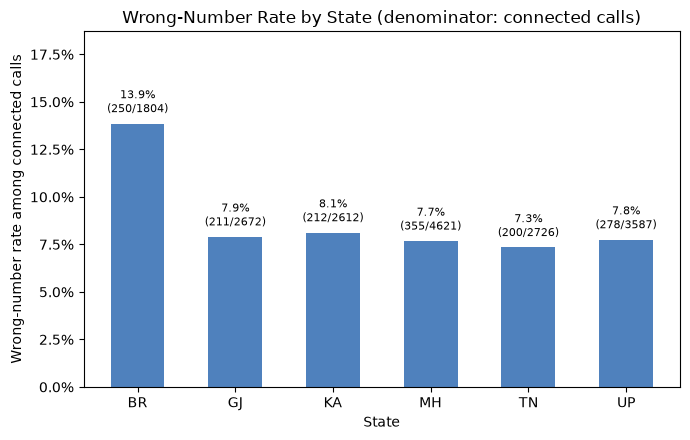

In [11]:
wr_state = (df.groupby("state")
              .agg(connected=("is_connected", "sum"), wrong=("is_wrong", "sum")))
assert (wr_state["connected"] > 0).all(), "state with zero connected denominator"
wr_state["wrong_rate"] = (wr_state["wrong"] / wr_state["connected"]).round(4)
print(wr_state.sort_values("wrong_rate", ascending=False).to_string())

fig, ax = plt.subplots(figsize=(7, 4.5))
ws = wr_state.sort_index()
bars = ax.bar(ws.index, ws["wrong_rate"], width=0.55,
              color=["#c00000" if r > 2 * ws["wrong_rate"].median() else "#4f81bd" for r in ws["wrong_rate"]])
for bar, (_, row) in zip(bars, ws.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004,
            f"{row['wrong_rate']:.1%}\n({int(row['wrong'])}/{int(row['connected'])})",
            ha="center", va="bottom", fontsize=8)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(xmax=1))
ax.set_xlabel("State")
ax.set_ylabel("Wrong-number rate among connected calls")
ax.set_ylim(0, ws["wrong_rate"].max() * 1.35)
ax.set_title("Wrong-Number Rate by State (denominator: connected calls)")
fig.tight_layout()
plt.show()

Segments: 48 | smallest connected denominator: 187

Top 10 batch x state segments by wrong-number rate:
             connected  wrong  wrong_rate
batch state                              
B7    BR           213    114      0.5352
B1    KA           323     36      0.1115
B8    MH           576     62      0.1076
B6    UP           443     46      0.1038
      BR           254     26      0.1024
B7    GJ           296     30      0.1014
B2    GJ           318     32      0.1006
B4    KA           329     33      0.1003
B2    BR           261     26      0.0996
B8    KA           328     30      0.0915


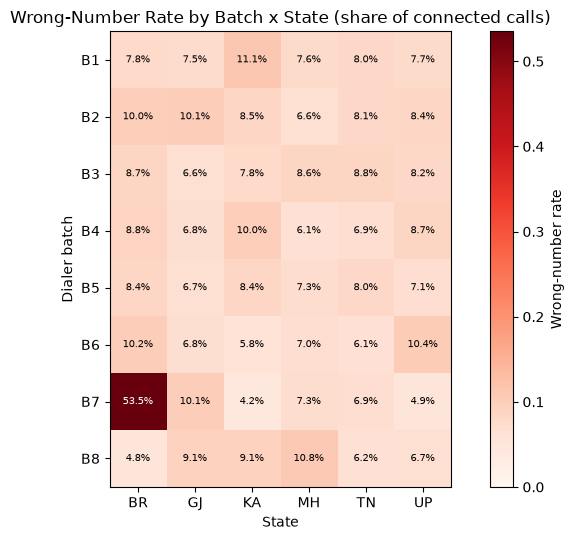

In [12]:
seg = (df.groupby(["batch", "state"])
         .agg(connected=("is_connected", "sum"), wrong=("is_wrong", "sum")))
assert (seg["connected"] > 0).all(), "batch-state cell with zero connected denominator"
seg["wrong_rate"] = seg["wrong"] / seg["connected"]
print(f"Segments: {len(seg)} | smallest connected denominator: {int(seg['connected'].min())}")
print("\nTop 10 batch x state segments by wrong-number rate:")
print(seg.sort_values("wrong_rate", ascending=False).head(10).round(4).to_string())

pivot = seg["wrong_rate"].unstack("state")   # rows=batch, cols=state
fig, ax = plt.subplots(figsize=(8, 5.5))
im = ax.imshow(pivot.values, cmap="Reds", vmin=0, vmax=pivot.values.max())
ax.set_xticks(range(pivot.shape[1]), pivot.columns)
ax.set_yticks(range(pivot.shape[0]), pivot.index)
ax.set_xlabel("State")
ax.set_ylabel("Dialer batch")
ax.set_title("Wrong-Number Rate by Batch x State (share of connected calls)")
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        ax.text(j, i, f"{pivot.values[i, j]:.1%}", ha="center", va="center", fontsize=7,
                color="white" if pivot.values[i, j] > pivot.values.max() * 0.55 else "black")
fig.colorbar(im, label="Wrong-number rate")
fig.tight_layout()
plt.show()

In [13]:
# Strongest anomaly = highest wrong-rate segment with a usable denominator (>=100 connected calls)
MIN_DEN = 100
candidates = seg[seg["connected"] >= MIN_DEN]
top_label = candidates["wrong_rate"].idxmax()
top_rate = candidates.loc[top_label, "wrong_rate"]
tb, ts = top_label
print(f"Strongest segment: batch {tb} x state {ts}  (min-denominator filter: {MIN_DEN} connected calls)")

mask_an = (df["batch"] == tb) & (df["state"] == ts)
groups = {
    f"{tb} x {ts} (anomaly)": df[mask_an],
    "rest of data":           df[~mask_an],
    f"rest of batch {tb}":    df[(df["batch"] == tb) & ~df["state"].eq(ts)],
    f"rest of state {ts}":    df[(df["state"] == ts) & ~df["batch"].eq(tb)],
}
rows = []
for name, d in groups.items():
    w, c = int(d["is_wrong"].sum()), int(d["is_connected"].sum())
    rows.append({"group": name, "wrong": w, "connected": c, "wrong_rate": w / c})
cmp_tbl = pd.DataFrame(rows).set_index("group")
print("\n" + cmp_tbl.round(4).to_string())

def z_test(w1, n1, w2, n2):
    p1, p2 = w1/n1, w2/n2
    pp = (w1 + w2) / (n1 + n2)
    se = np.sqrt(pp * (1 - pp) * (1/n1 + 1/n2))
    z = (p1 - p2) / se
    from math import erfc, sqrt
    p_value = erfc(abs(z) / sqrt(2))
    return z, p_value

an = cmp_tbl.iloc[0]
rest = cmp_tbl.loc["rest of data"]
pp_diff = (an["wrong_rate"] - rest["wrong_rate"]) * 100
rr = an["wrong_rate"] / rest["wrong_rate"]
z, p_value = z_test(an["wrong"], an["connected"], rest["wrong"], rest["connected"])
print(f"\nvs rest of data:  +{pp_diff:.1f} percentage points | relative risk = {rr:.2f}x")
print(f"Two-proportion z-test: z = {z:.1f}, p-value = {p_value:.3g} (statistically significant)")

for other in ["rest of data", f"rest of batch {tb}", f"rest of state {ts}"]:
    r = cmp_tbl.loc[other]
    print(f"vs {other:18s}: +{(an['wrong_rate'] - r['wrong_rate'])*100:5.1f} pp | RR = {an['wrong_rate']/r['wrong_rate']:.2f}x  "
          f"({int(an['wrong'])}/{int(an['connected'])} vs {int(r['wrong'])}/{int(r['connected'])})")

Strongest segment: batch B7 x state BR  (min-denominator filter: 100 connected calls)

                   wrong  connected  wrong_rate
group                                          
B7 x BR (anomaly)    114        213      0.5352
rest of data        1392      17809      0.0782
rest of batch B7     137       2071      0.0662
rest of state BR     136       1591      0.0855

vs rest of data:  +45.7 percentage points | relative risk = 6.85x
Two-proportion z-test: z = 24.0, p-value = 7.06e-127 (statistically significant)
vs rest of data      : + 45.7 pp | RR = 6.85x  (114/213 vs 1392/17809)
vs rest of batch B7  : + 46.9 pp | RR = 8.09x  (114/213 vs 137/2071)
vs rest of state BR  : + 45.0 pp | RR = 6.26x  (114/213 vs 136/1591)


In [14]:
# Does the contamination also show up downstream? RPC share of connected, and PTP per RPC, by group
rows = []
for name, d in groups.items():
    c = int(d["is_connected"].sum()); r_ = int(d["is_rpc"].sum()); p_ = int(d["is_ptp"].sum())
    rows.append({"group": name, "connected": c, "rpc": r_, "ptps": p_,
                 "rpc_per_connected": r_ / c, "ptp_per_rpc": p_ / r_ if r_ else np.nan})
down = pd.DataFrame(rows).set_index("group")
print(down.round(4).to_string())

                   connected    rpc  ptps  rpc_per_connected  ptp_per_rpc
group                                                                    
B7 x BR (anomaly)        213     99    30             0.4648       0.3030
rest of data           17809  16417  3862             0.9218       0.2352
rest of batch B7        2071   1934   421             0.9338       0.2177
rest of state BR        1591   1455   358             0.9145       0.2460


### Interpretation (observed association, not proven cause)

- The anomaly is concentrated in **one cell of the grid**: batch × state. Batch-level (11.0%) and state-level (13.9%) views dilute it; the joint view shows a ~54% wrong-number rate against a ~8% baseline everywhere else.
- The comparison is fair: the same segment is compared against (a) all other calls, (b) the same batch in other states, and (c) the same state in other batches — the effect survives all three, so it is specific to the **B7-in-BR list slice**, not to batch B7 or Bihar generally.
- **Operational reading:** roughly 100 of the 213 answered B7-BR calls reached the wrong party. That is a phone-list integrity problem (stale/recycled numbers or a bad list slice from the vendor for that segment), not an agent-performance or script problem.
- **Supported action:** suppress the B7-BR slice from dialing, re-verify or re-source those numbers, and audit how that slice was produced (vendor, refresh date, source file) before resuming. Monitor the segment-level wrong-number rate weekly with the same denominator (connected calls) and require the denominator ≥100 before flagging.
- **Caveat:** this is a correlational finding from one month of data. The data shows *where* the waste is, not *why* it exists; confirm the list source/refresh history before attributing cause to a specific vendor or process.